<img src="https://github.com/hernancontigiani/ceia_memorias_especializacion/raw/master/Figures/logoFIUBA.jpg" width="500" align="center">

# **Visión por Computadora 3D**
# **Clase 5, DUSt3R vs MASt3R**

MASt3R es DUSt3R con dos cambios:
* una cabeza nueva que da un descriptor por píxel, entrenada para matching
* pointmaps métricos: en metros, no en una escala normalizada por par

* clonamos MASt3R, tambien bajamos DUSt3R, que viene como submodulo
* clonamos VGGT para usar sus fotos de ejemplo
* instalamos roma, para rotaciones en torch

In [ ]:
!git clone -q --recursive https://github.com/naver/mast3r.git
!git clone -q --depth 1 https://github.com/facebookresearch/vggt.git
!pip install -q roma trimesh scikit-learn

importamos lo necesario

In [ ]:
import sys
import time
import pathlib
import numpy as np
import cv2
import torch
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from scipy.spatial import cKDTree # búsqueda de vecinos más cercanos en 3D (matching de DUSt3R)
sys.path.append("mast3r")
import mast3r.utils.path_to_dust3r # agrega el submódulo dust3r al path
from mast3r.model import AsymmetricMASt3R # modelo MASt3R
from mast3r.fast_nn import fast_reciprocal_NNs # matching rápido por descriptores (MASt3R)
from mast3r.cloud_opt.sparse_ga import sparse_global_alignment # alineación global dispersa (MASt3R-SfM)
from dust3r.model import AsymmetricCroCo3DStereo # modelo DUSt3R
from dust3r.inference import inference # la carga de imágenes, la creación de pares y el alineador global denso
from dust3r.utils.image import load_images
from dust3r.image_pairs import make_pairs
from dust3r.cloud_opt import global_aligner, GlobalAlignerMode # alineación global densa (DUSt3R)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(device, torch.cuda.get_device_name() if device == "cuda" else "")

##**0.- Los dos modelos**

cargamos ambos modelos preentrenados desde HuggingFace y contamos sus parámetros

* los dos tienen encoder ViT-Large + decoder ViT-Base. El decoder es "asimétrico": dos ramas que intercambian información entre las dos imágenes con cross-attention
* el decoder es asimetrico porque la imagen 1 es la referencia: su decoder predice sus puntos 3D en su propia cámara, mientras que la imagen 2 tiene que predecir sus puntos 3D en la cámara de la imagen 1, así que su rama debe "entender" la pose relativa.
* DUSt3R usa cabeza dpt (convierte los tokens del transformer en una salida por píxel), MASt3R usa catmlpdpt: la DPT para los puntos 3D más un MLP para los descriptores
* _metric en el nombre de MASt3R indica que se entrenó en escala métrica.

In [ ]:
modelos = {"DUSt3R": AsymmetricCroCo3DStereo.from_pretrained("naver/DUSt3R_ViTLarge_BaseDecoder_512_dpt").to(device).eval(),
           "MASt3R": AsymmetricMASt3R.from_pretrained("naver/MASt3R_ViTLarge_BaseDecoder_512_catmlpdpt_metric").to(device).eval()}
for nombre, m in modelos.items():
    print(f"{nombre}: {sum(p.numel() for p in m.parameters()) / 1e6:.0f} M parámetros")

una función corre un modelo sobre un par de fotos (en un solo orden) y devuelve todo en numpy. MASt3R además devuelve el descriptor de cada píxel

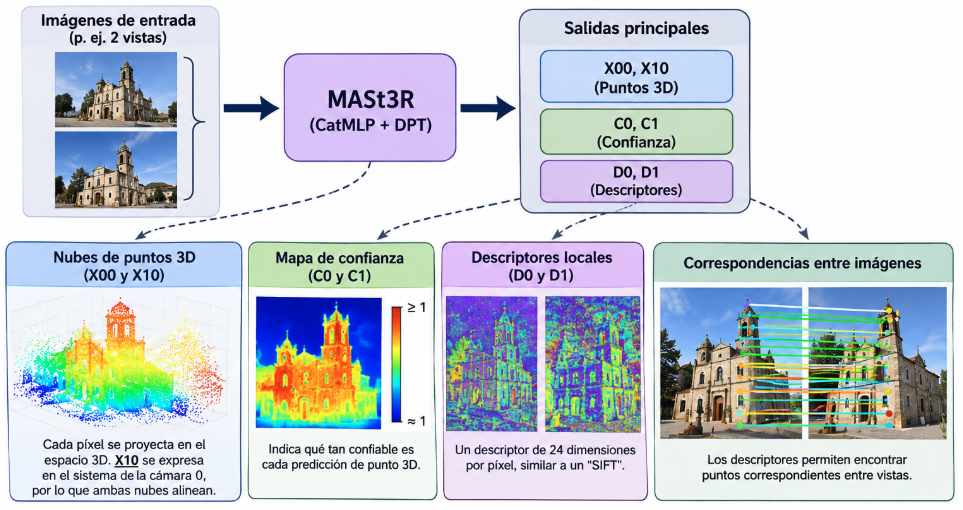

In [ ]:
def correr_par(nombre, ruta0, ruta1):
    # redimensiona las fotos a 512 px de ancho
    imgs = load_images([str(ruta0), str(ruta1)], size=512, verbose=False)
    t0 = time.time()
    # ejecuta la red y se mide cuánto tarda
    out = inference([tuple(imgs)], modelos[nombre], device, batch_size=1, verbose=False)
    t = time.time() - t0
    # Devuelve un diccionario con
    r = {"X00": out["pred1"]["pts3d"][0].numpy(), # un punto 3D por cada píxel de la foto 0
         "X10": out["pred2"]["pts3d_in_other_view"][0].numpy(), # un punto 3D por cada píxel de la foto 1, pero visto desde la cámara 0. Por eso las dos fotos ya salen "pegadas" en el mismo espacio
         "C0": out["pred1"]["conf"][0].numpy(), "C1": out["pred2"]["conf"][0].numpy(), # cuánto confía el modelo en cada punto
         "rgb": [(im["img"][0].permute(1, 2, 0).numpy() * 0.5 + 0.5).clip(0, 1) for im in imgs], # las fotos devueltas a [0, 1], para dibujar y colorear la nube
         "tiempo": t}
    # si el modelo es MASt3R, también tenemos una "huella digital" de cada píxel (el descriptor), que sirve para reconocerlo en la otra foto
    if "desc" in out["pred1"]:
        r["D0"], r["D1"] = out["pred1"]["desc"][0], out["pred2"]["desc"][0] # (H, W, 24), los dejamos en torch
    return r

Las dos funciones buscan qué píxel de la foto 0 corresponde a qué píxel de la foto 1, como el matching de SIFT en SfM:

* DUSt3R empareja píxeles cuyos puntos 3D quedaron cerca
* MASt3R empareja píxeles cuyas huellas digitales se parecen

In [ ]:
def parejas_dust3r(r, cuantil=50):
    # tamaño de la imagen
    H, W = r["C0"].shape
    # cada píxel guarda su propia posición (x, y)
    jj, ii = np.mgrid[0:H, 0:W]
    pix = np.stack([ii, jj], -1)
    # nos quedamos solo con la mitad de píxeles más confiables
    m0, m1 = r["C0"] > np.percentile(r["C0"], cuantil), r["C1"] > np.percentile(r["C1"], cuantil)
    # P = puntos 3D, u = posición en la imagen (de los píxeles que quedaron)
    P0, P1, u0, u1 = r["X00"][m0], r["X10"][m1], pix[m0], pix[m1]
    # para cada punto de la foto 0, el punto 3D más cercano en la foto 1
    _, de0 = cKDTree(P1).query(P0)
    # y al reves: para cada punto de la foto 1, el más cercano en la foto 0
    _, de1 = cKDTree(P0).query(P1)
    # solo valen las parejas que se eligen mutuamente
    recip = de1[de0] == np.arange(len(P0))
    # devuelve los píxeles emparejados: foto 0 y foto 1
    return u0[recip].astype(float), u1[de0[recip]].astype(float)

def parejas_mast3r(r):
    # empareja píxeles con descriptores parecidos (y que se elijan mutuamente)
    # para ir rápido, empieza con un píxel cada 8 y va afinando
    a, b = fast_reciprocal_NNs(r["D0"], r["D1"], subsample_or_initxy1=8, device=device, dist="dot", block_size=2 ** 13)
    # tamaño de la imagen
    H, W = r["C0"].shape
    # descarta las parejas pegadas al borde (a menos de 3 px)
    ok = ((a[:, 0] >= 3) & (a[:, 0] < W - 3) & (a[:, 1] >= 3) & (a[:, 1] < H - 3) &
          (b[:, 0] >= 3) & (b[:, 0] < W - 3) & (b[:, 1] >= 3) & (b[:, 1] < H - 3))
    # devuelve los píxeles emparejados: foto 0 y foto 1
    return a[ok].astype(float), b[ok].astype(float)

# para llamar a cada función por el nombre del modelo
PAREJAS = {"DUSt3R": parejas_dust3r, "MASt3R": parejas_mast3r}

## **1.- Ronda 1: pointmaps**

el par imposible: la excavadora vista casi desde lados opuestos

In [ ]:
# las dos fotos: la excavadora vista casi desde lados opuestos
F0, F1 = "vggt/examples/kitchen/images/00.png", "vggt/examples/kitchen/images/12.png"
# corre los dos modelos (DUSt3R y MASt3R) sobre ese par
res = {n: correr_par(n, F0, F1) for n in modelos}
# guarda las dos imágenes (ya achicadas) para dibujarlas después
I0, I1 = res["DUSt3R"]["rgb"]
# alto y ancho de esas imágenes
H, W = I0.shape[:2]
# muestra cuánto tardó cada modelo
for n, r in res.items():
  print(f"{n}: {r['tiempo']:.2f} s")

para cada modelo: la foto 1, X¹⁰ (la foto 1 en la cámara 0) pintado como color, con (x, y, z) → (R, G, B), y la confianza. Si la geometría es coherente, los colores cambian suavemente siguiendo la forma de los objetos; las manchas o saltos marcan dónde la red se equivocó, y suelen coincidir con las zonas de baja confianza

In [ ]:
# convierte un pointmap (x, y, z por píxel) en una imagen de colores (R, G, B)
def como_color(X, C):
    # ignora el 20% de píxeles menos confiables al calcular el rango
    m = C > np.percentile(C, 20)
    # rango de x, y, z (sin los valores extremos: percentil 2 a 98)
    lo, hi = np.percentile(X[m], 2, axis=0), np.percentile(X[m], 98, axis=0)
    # lleva x, y, z a [0, 1] → se usan como R, G, B
    return ((X - lo) / (hi - lo)).clip(0, 1)

# grilla de 2 filas (una por modelo) × 3 columnas
fig, ax = plt.subplots(2, 3, figsize=(18, 8))
for fila, (n, r) in zip(ax, res.items()):
    # columna 1: la foto 1 original
    fila[0].imshow(I1)
    fila[0].set_title(n)
    # columna 2: el pointmap X10 pintado como colores
    fila[1].imshow(como_color(r["X10"], r["C1"]))
    fila[1].set_title("X¹⁰: foto 1 en la cámara 0")
    # columna 3: la confianza de cada píxel (claro = confía más)
    im = fila[2].imshow(r["C1"], cmap="magma")
    fila[2].set_title("confianza")
    plt.colorbar(im, ax=fila[2], fraction=0.03)
# saca los ejes de todos los gráficos
for a in ax.ravel(): a.axis("off")
plt.show()

* Columna 2: la posición 3D de cada píxel se muestra como color. La mesa es un degradé suave porque es un plano, y la excavadora es un bloque con borde nítido porque sobresale. Los colores no siguen la izquierda/derecha de la foto porque las coordenadas están en la cámara 0, que mira desde el lado opuesto.
 * Columna 3: la confianza es alta en la mesa cercana y baja en el fondo lejano y en los bordes de la excavadora.
* Comparación: las dos redes dan casi la misma geometría, pero la confianza de MASt3R es más nítida. Eso anticipa que es más preciso.
---

* **nube_par** toma el resultado de un modelo y arma su nube: los puntos 3D confiables de las dos fotos (X00 y X10) con sus colores. Devuelve una lista de pares (puntos, colores).
* **lado_a_lado** recibe las nubes de todos los modelos (un diccionario {"DUSt3R": ..., "MASt3R": ...}) y crea una figura con una columna 3D por modelo. Para dibujar cada columna llama a trazas.
* **trazas** recibe una nube y la deja lista para plotly: junta los puntos, toma 50.000 al azar, quita los extremos y gira los ejes para que "arriba" quede arriba.

In [ ]:
# prepara una nube de puntos 3D para dibujarla con plotly
def trazas(listas, n=50000):
    # junta los puntos (y sus colores) de todas las fotos en una sola lista
    P = np.concatenate([p for p, _ in listas]); col = np.concatenate([c for _, c in listas])
    # toma 50.000 puntos al azar para que el gráfico no sea lento
    idx = np.random.default_rng(0).choice(len(P), min(n, len(P)), replace=False); P, col = P[idx], col[idx]
    # quita los puntos extremos (fuera del percentil 1 a 99) para que no achiquen la escena
    lo, hi = np.percentile(P, 1, axis=0), np.percentile(P, 99, axis=0)
    k = np.all((P > lo) & (P < hi), axis=1); P, col = P[k], col[k]
    # dibuja cada punto con el color de su píxel
    # ejes cambiados (X, Z, −Y): en la cámara Y apunta hacia abajo, así "arriba" queda arriba
    return go.Scatter3d(x=P[:, 0], y=P[:, 2], z=-P[:, 1], mode="markers", showlegend=False,
                        marker=dict(size=1.5, color=[f"rgb({r * 255:.0f},{g * 255:.0f},{b * 255:.0f})" for r, g, b in col]))

# dibuja varias nubes una al lado de la otra (una por modelo)
def lado_a_lado(nubes, titulo):
    from plotly.subplots import make_subplots
    # una columna 3D por cada nube
    fig = make_subplots(rows=1, cols=len(nubes), specs=[[{"type": "scene"}] * len(nubes)], subplot_titles=list(nubes))
    # agrega cada nube en su columna
    for k, listas in enumerate(nubes.values()):
        fig.add_trace(trazas(listas), row=1, col=k + 1)
    # proporciones reales (sin deformar) y sin ejes visibles
    ejes = dict(aspectmode="data", xaxis_visible=False, yaxis_visible=False, zaxis_visible=False)
    fig.update_layout(height=550, title=titulo, margin=dict(l=0, r=0, t=60, b=0), **{f"scene{'' if k == 0 else k + 1}": ejes for k in range(len(nubes))})
    fig.show()

# arma la nube de un par: los puntos de las dos fotos con sus colores
def nube_par(r):
    # quita el 30% de píxeles menos confiables de cada foto
    m0, m1 = r["C0"] > np.percentile(r["C0"], 30), r["C1"] > np.percentile(r["C1"], 30)
    # foto 0 (X00) + foto 1 (X10): las dos ya están en la cámara 0, no hay que alinear nada
    return [(r["X00"][m0], r["rgb"][0][m0]), (r["X10"][m1], r["rgb"][1][m1])]

# dibuja la nube de DUSt3R y la de MASt3R lado a lado
lado_a_lado({n: nube_par(r) for n, r in res.items()}, "las dos fotos en una nube, según cada modelo")

## **2.- Ronda 2: parejas**

Comprobamos si las parejas son buenas usando la geometría de dos cámaras:

* Con RANSAC estimamos la matriz F, que describe cómo se relacionan las dos cámaras.
* Contamos cuántas parejas cumplen con F (robustez).
* Medimos por cuántos píxeles fallan las que cumplen (precisión).

In [ ]:
# distancia de Sampson: cuánto se aleja cada pareja de cumplir la geometría epipolar (en píxeles²)
def sampson(F, x1, x2):
    # pasa los píxeles a coordenadas homogéneas: (x, y) → (x, y, 1)
    a, b = np.c_[x1, np.ones(len(x1))], np.c_[x2, np.ones(len(x2))]
    # Fa = recta epipolar de cada punto de la foto 0 en la foto 1
    # Fb = recta epipolar de cada punto de la foto 1 en la foto 0
    Fa, Fb = a @ F.T, b @ F
    # error epipolar (x2ᵀ F x1)² dividido por la "pendiente" de las rectas → error aproximado en píxeles²
    return (b * Fa).sum(1) ** 2 / (Fa[:, 0] ** 2 + Fa[:, 1] ** 2 + Fb[:, 0] ** 2 + Fb[:, 1] ** 2)

parejas = {}
for n, r in res.items():
    # saca las parejas con el método de cada modelo y mide el tiempo
    t0 = time.time(); a, b = PAREJAS[n](r); t = time.time() - t0
    # estima la matriz fundamental F con RANSAC (umbral 2 px)
    # ok = qué parejas son inliers (consistentes con esa F)
    F, ok = cv2.findFundamentalMat(a, b, cv2.FM_RANSAC, 2.0, 0.999); ok = ok.ravel() > 0
    # distancia de Sampson de los inliers, en píxeles
    d = np.sqrt(sampson(F, a[ok], b[ok]))
    # guarda las parejas para dibujarlas después
    parejas[n] = (a, b, ok)
    # muestra: cuántas parejas, % de inliers y error mediano
    print(f"{n}: {len(a):6d} parejas en {t:.2f} s | consistentes {ok.mean():.0%} | distancia mediana a la recta epipolar {np.median(d):.2f} px")

In [ ]:
fig, ax = plt.subplots(2, 1, figsize=(16, 11))
for a_, (n, (a, b, ok)) in zip(ax, parejas.items()):
    a_.imshow(np.hstack([I0, I1])); a_.axis("off")
    sel = np.random.default_rng(1).choice(len(a), min(50, len(a)), replace=False)
    for k in sel:
        a_.plot([a[k, 0], b[k, 0] + W], [a[k, 1], b[k, 1]], "-o", color="lime" if ok[k] else "red", lw=0.9, ms=2.5)
    a_.set_title(f"{n}: 50 parejas al azar (verde: consistentes, rojo: no)")
plt.tight_layout(); plt.show()

* DUSt3R empareja por cercanía de los puntos 3D. Saca muchas parejas, incluso en este par tan difícil, pero son imprecisas: los pointmaps son suaves, así que varios píxeles vecinos caen casi en el mismo punto 3D y el vecino más cercano “se corre” algunos píxeles. Resultado: menos consistentes y mayor distancia a la epipolar.
* MASt3R empareja por descriptores entrenados para matching, que distinguen píxeles vecinos. Debería sacar parejas igual de robustas pero bastante más precisas, con un porcentaje de consistentes más alto y una distancia mediana menor.

## **3.- Ronda 3: muchas fotos**

* **DUSt3R:** alineación global **densa**: una escala y una pose por par, y ajusta todos los píxeles (notebook 6)
* **MASt3R:** alineación global **dispersa** (MASt3R-SfM): primero hace matching con los descriptores, después alinea solo esos puntos en 3D y termina refinando el error de reproyección en 2D, como un bundle adjustment


In [ ]:
ROOM = sorted(str(p) for p in pathlib.Path("vggt/examples/room/images").iterdir())
fig, ax = plt.subplots(1, len(ROOM), figsize=(20, 3))
for a_, f in zip(ax, ROOM): a_.imshow(plt.imread(f)); a_.axis("off")
plt.show()

DUSt3R

In [ ]:
t0 = time.time()
# carga las 8 fotos del cuarto, achicadas a 512 px
imgs = load_images(ROOM, size=512, verbose=False)
# arma todos los pares posibles (en los dos órdenes) y corre DUSt3R sobre cada uno
salida = inference(make_pairs(imgs, scene_graph="complete", prefilter=None, symmetrize=True), modelos["DUSt3R"], device, batch_size=1, verbose=False)
# prepara la alineación global: unir todos los pares en un solo sistema 3D
escena = global_aligner(salida, device=device, mode=GlobalAlignerMode.PointCloudOptimizer)
# optimiza poses, escalas y profundidades (300 pasos, arrancando por los pares más confiables)
escena.compute_global_alignment(init="mst", niter=300, schedule="cosine", lr=0.01)
# tiempo total de DUSt3R
t_dust3r = time.time() - t0
# puntos 3D de cada foto, ya en el sistema común
pts = [p.detach().cpu().numpy() for p in escena.get_pts3d()]
# máscara de píxeles confiables de cada foto
masks = [m.cpu().numpy() for m in escena.get_masks()]
# nube final: puntos confiables de cada foto con su color
nube_dust3r = [(p[m], c[m]) for p, m, c in zip(pts, masks, escena.imgs)]
# focal estimada para cada foto
f_dust3r = escena.get_focals().detach().cpu().numpy().ravel()

# libera memoria de la GPU
del salida, escena
torch.cuda.empty_cache()

# tiempo y las focales
print(f"DUSt3R: {t_dust3r:.0f} s | focales {f_dust3r.round(0)}")

* para cada par se preguntó cómo encajan entre sí y anotó qué tan segura estaba de la respuesta (ese es el "score").
* las fotos 1 y 4 son las más débiles.
* las "focales" (380 a 436) son el zoom que cree que tenía la cámara en cada foto

MASt3R: sparse_global_alignment guarda resultados intermedios en una carpeta de caché. Usamos los parámetros por defecto de la demo de los autores

In [ ]:
t0 = time.time()
# carga las 8 fotos del cuarto, achicadas a 512 px
imgs = load_images(ROOM, size=512, verbose=False)
# arma todos los pares posibles (en los dos órdenes)
pares = make_pairs(imgs, scene_graph="complete", prefilter=None, symmetrize=True)
# corre MASt3R en cada par, empareja con descriptores y une todo en un solo sistema 3D:
# etapa 1: alinea los puntos emparejados en 3D (lr1, niter1)
# etapa 2: afina minimizando el error de reproyección en 2D, como un bundle adjustment (lr2, niter2)
# también ajusta las profundidades, estima una focal por foto y usa solo parejas con confianza > 5
escena = sparse_global_alignment(ROOM, pares, "cache_mast3r", modelos["MASt3R"], lr1=0.07, niter1=300, lr2=0.014, niter2=300,
                                 device=device, opt_depth=True, shared_intrinsics=False, matching_conf_thr=5.0)
# tiempo total de MASt3R
t_mast3r = time.time() - t0
# puntos 3D densos de cada foto (ya en el sistema común) y su confianza
pts, _, confs = escena.get_dense_pts3d(clean_depth=True)
# colores de cada foto
rgbs = escena.imgs
# nube final
nube_mast3r = []
for p, c, im in zip(pts, confs, rgbs):
    # pasa puntos, confianza y colores a listas planas (un elemento por píxel)
    p = p.detach().cpu().numpy().reshape(-1, 3); c = c.detach().cpu().numpy().ravel(); im = np.asarray(im).reshape(-1, 3)
    # se queda solo con los puntos confiables (confianza > 1.5) y su color
    nube_mast3r.append((p[c > 1.5], im[c > 1.5]))
# focal estimada para cada foto
f_mast3r = escena.get_focals().detach().cpu().numpy().ravel()
# muestra el tiempo y las focales
print(f"MASt3R: {t_mast3r:.0f} s | focales {f_mast3r.round(0)}")

* En cada par de fotos buscó puntos concretos que se repiten (una esquina, una mancha) y después acomodó las cámaras para que esos puntos coincidieran.
* El ajuste final quedó con un desfase de unos 0.4 píxeles, así que los puntos encajan muy bien.
* Las fotos 1 y 4 vuelven a ser las más débiles: son las que tienen el zoom más distinto al resto.
* Las "focales" (338 a 444) son el zoom que cree que tenía la cámara en cada foto. Varían más que en DUSt3R, sobre todo por esas dos fotos.

In [ ]:
lado_a_lado({"DUSt3R (alineación densa)": nube_dust3r, "MASt3R (alineación dispersa)": nube_mast3r}, "el cuarto con 8 fotos")

las focales: las 8 fotos son de la misma cámara, así que deberían parecerse entre sí

In [ ]:
for n, f in [("DUSt3R", f_dust3r), ("MASt3R", f_mast3r)]:
    print(f"{n}: focal media {f.mean():.0f} px, variación entre fotos {f.std() / f.mean():.0%}")

## **4.- Fotos propias**

Este espacio es para pasar fotos propias de la misma escena, desde puntos de vista distintos, y mirar cómo lo hace cada método:
* X¹⁰ como color y la confianza
* las dos fotos en una nube 3D
* las parejas de cada método, con RANSAC y la distancia a la epipolar



In [ ]:
FOTO_0 = ""  # ruta a tu primera foto, por ejemplo "/content/mi_foto_0.jpg" (vacío = subirla)
FOTO_1 = ""  # ruta a tu segunda foto (vacío = subirla)

# si falta alguna ruta, abre el diálogo para subir las dos fotos
if not FOTO_0 or not FOTO_1:
    from google.colab import files
    print("elige DOS fotos")
    subidas = list(files.upload())
    assert len(subidas) >= 2, "hay que subir dos fotos"
    FOTO_0, FOTO_1 = subidas[:2]
print("foto 0:", FOTO_0, "| foto 1:", FOTO_1)

una función que hace todo con tus dos fotos. Primero lleva la foto 1 al tamaño de la foto 0, porque las funciones de parejas suponen que las dos imágenes miden lo mismo

In [ ]:
# Dejamos las dos fotos del mismo tamaño y las guardamos como png
def preparar(ruta0, ruta1, carpeta="mis_fotos"):
    # Creamos la carpeta de salida si no existe
    pathlib.Path(carpeta).mkdir(exist_ok=True)
    # Leemos las dos fotos (OpenCV las carga en BGR)
    im0, im1 = cv2.imread(str(ruta0)), cv2.imread(str(ruta1))
    # Si alguna no se pudo leer, cortamos con un error claro
    if im0 is None or im1 is None:
        raise ValueError("no se pudo leer alguna de las fotos (usa jpg o png)")
    # Llevamos la foto 1 al tamaño de la foto 0
    im1 = cv2.resize(im1, (im0.shape[1], im0.shape[0]))
    # Definimos las rutas de salida de las dos fotos
    p0, p1 = f"{carpeta}/foto0.png", f"{carpeta}/foto1.png"
    # Guardamos las dos fotos ya igualadas
    cv2.imwrite(p0, im0); cv2.imwrite(p1, im1)
    return p0, p1

def comparar(ruta0, ruta1):
    # Preparamos las fotos y obtenemos sus rutas
    p0, p1 = preparar(ruta0, ruta1)
    # Corremos los dos modelos sobre el par
    res_mio = {n: correr_par(n, p0, p1) for n in modelos}
    # Tomamos las dos fotos tal como las ve el modelo (ya redimensionadas)
    J0, J1 = res_mio["DUSt3R"]["rgb"]
    # Guardamos alto y ancho (el ancho nos sirve para desplazar la foto 1 en el gráfico de parejas)
    h, w = J0.shape[:2]
    # Mostramos el tiempo que tardó cada modelo en procesar el par
    for n, r in res_mio.items():
        print(f"{n}: {r['tiempo']:.2f} s")

    # 1) Mostramos las dos fotos, X10 como color y la confianza, una fila por modelo
    fig, ax = plt.subplots(2, 4, figsize=(22, 8))
    for fila, (n, r) in zip(ax, res_mio.items()):
        fila[0].imshow(J0); fila[0].set_title(f"{n}: foto 0")
        fila[1].imshow(J1); fila[1].set_title("foto 1")
        fila[2].imshow(como_color(r["X10"], r["C1"])); fila[2].set_title("X¹⁰: foto 1 en la cámara 0")
        im = fila[3].imshow(r["C1"], cmap="magma"); fila[3].set_title("confianza")
        plt.colorbar(im, ax=fila[3], fraction=0.03)
    for a_ in ax.ravel(): a_.axis("off")
    plt.show()

    # 2) Mostramos las dos fotos en una nube 3D, según cada modelo
    lado_a_lado({n: nube_par(r) for n, r in res_mio.items()}, "tus dos fotos en una nube, según cada modelo")

    # 3) Mostramos las parejas de cada método, verificadas con RANSAC sobre F
    fig, ax = plt.subplots(2, 1, figsize=(16, 11))
    for a_, (n, r) in zip(ax, res_mio.items()):
        # Buscamos las parejas de píxeles con el método de este modelo y medimos cuánto tarda
        t0 = time.time(); a, b = PAREJAS[n](r); t = time.time() - t0
        a_.imshow(np.hstack([J0, J1])); a_.axis("off")
        # Con menos de 8 parejas no podemos estimar la matriz fundamental
        if len(a) < 8:
            print(f"{n}: solo {len(a)} parejas, no alcanza para estimar F")
            a_.set_title(f"{n}: muy pocas parejas"); continue
        # Estimamos la matriz fundamental F con RANSAC (umbral 2 px, 99.9 % de confianza)
        # ok nos marca qué parejas son consistentes con esa F
        F, ok = cv2.findFundamentalMat(a, b, cv2.FM_RANSAC, 2.0, 0.999)
        # Si RANSAC falla, no contamos ninguna pareja como consistente
        if F is None:
            print(f"{n}: {len(a)} parejas, pero RANSAC no encontró una F")
            ok = np.zeros(len(a), bool)
        else:
            # Pasamos la máscara de RANSAC a un vector de True/False
            ok = ok.ravel() > 0
            # Calculamos la distancia de Sampson (en px) de cada pareja consistente a su recta epipolar
            # Usamos F[:3] por si OpenCV devuelve varias F apiladas: nos quedamos con la primera
            d = np.sqrt(sampson(F[:3], a[ok], b[ok]))
            # Resumimos: cuántas parejas, cuánto tardó, % consistentes y error típico
            print(f"{n}: {len(a):6d} parejas en {t:.2f} s | consistentes {ok.mean():.0%} | distancia mediana a la recta epipolar {np.median(d):.2f} px")
        # Elegimos 50 parejas al azar: verde = consistente, rojo = no
        sel = np.random.default_rng(1).choice(len(a), min(50, len(a)), replace=False)
        for k in sel:
            a_.plot([a[k, 0], b[k, 0] + w], [a[k, 1], b[k, 1]], "-o", color="lime" if ok[k] else "red", lw=0.9, ms=2.5)
        a_.set_title(f"{n}: 50 parejas al azar (verde: consistentes, rojo: no)")
    plt.tight_layout(); plt.show()
    # Devolvemos los resultados de los dos modelos por si queremos seguir analizándolos
    return res_mio

In [ ]:
res_mio = comparar(FOTO_0, FOTO_1)